## Border analysis

In [1]:
import sys
import os

# Add the project root to the system path to import local modules
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '../..')))

In [2]:
from python.dualbranch.ham10000_dataset_manager import HAM10000DatasetManager
from python.utils.lesion_mask import create_simple_binary_mask, boundary_extraction
from python.utils.lesions_border_analysis import calculate_irregularity_index, preprocess_lesion
from skimage.morphology import convex_hull_image
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from skimage import io

In [3]:
# load the dataset manager
dataset_manager = HAM10000DatasetManager(data_dir="../../data")

# load the dataset
# dataset = dataset_manager.load_dataset(data_dir="../../data")
dataset_manager.load_cleaned_metadata()

### Get specific image from dataset, extract binary mask, and outline

In [4]:
# load specific sample image and display image id, lesions type image with outlien mask and rotated binary mask with centroid
image_id = "ISIC_0027409"

image_id, lesion_type, image = dataset_manager.get_sample_image()

binary_mask = create_simple_binary_mask(image=image)

outline = boundary_extraction(binary_mask)

### Calculate area-based irregularity index and visualize concavities

Overall Irregularity Index: 0.5239
Most Significant Feature Index: 0.2347
Concavity Areas (px): [124.0, 65.0, 623.0, 85.0, 155.0, 215.0, 68.0, 54.0, 2.0]


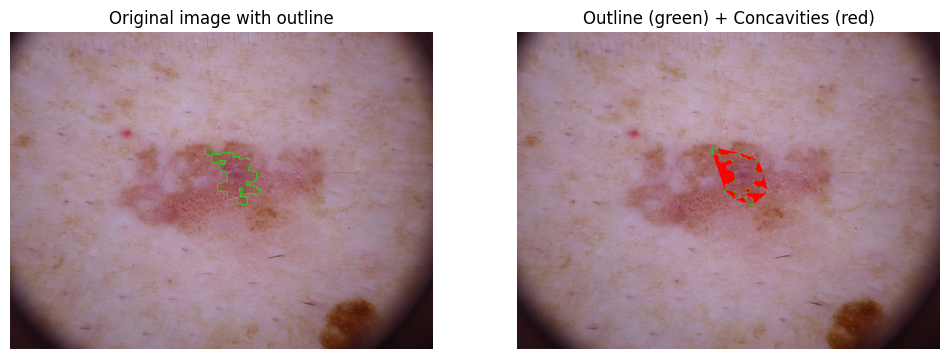

In [5]:
# Compute index from current binary_mask
result = calculate_irregularity_index(binary_mask)
print(f"Overall Irregularity Index: {result['overall_irregularity_index']:.4f}")
print(f"Most Significant Feature Index: {result['most_significant_index']:.4f}")
print(f"Concavity Areas (px): {result['feature_areas']}")

# Build visualization: convex hull vs original mask; highlight concavities
cleaned_mask = preprocess_lesion(binary_mask)
hull = convex_hull_image(cleaned_mask.astype(bool))
concavities = (hull & ~cleaned_mask.astype(bool))

overlay = image.copy()
# Ensure overlay is RGB
if overlay.ndim == 2:
    overlay = np.stack([overlay] * 3, axis=-1)

# Overlay original outline in green (uses 'outline' from previous cell)
overlay[outline > 0] = [0, 255, 0]
# Overlay concavities in red
overlay[concavities] = [255, 0, 0]

outline_overlay = image.copy()
outline_overlay[outline > 0] = [0, 255, 0]

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(outline_overlay)
axes[0].set_title("Original image with outline")
axes[0].axis('off')

axes[1].imshow(overlay)
axes[1].set_title("Outline (green) + Concavities (red)")
axes[1].axis('off')
plt.show()



RDV vs Irregularity Index Comparison by Lesion Type:
                rdv                      irregularity_index                  
               mean     std  min     max               mean     std  min  max
lesion_type                                                                  
mel          0.0975  0.1108  0.0  0.5714             0.2261  0.1914  0.0  1.0
nv           0.0580  0.1129  0.0  1.0000             0.1484  0.1689  0.0  1.0


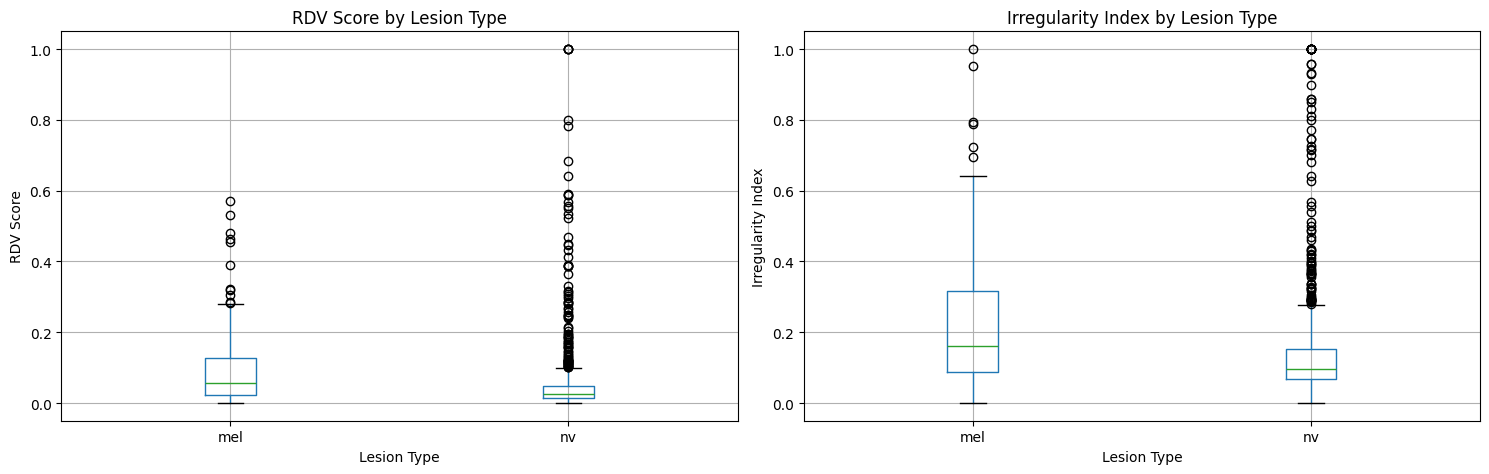


Correlation between RDV and Irregularity Index:
                         rdv  irregularity_index
rdv                 1.000000            0.923434
irregularity_index  0.923434            1.000000


In [9]:
# Compare RDV and irregularity index across lesion types for 1000 samples

# Get samples - reuse or create new
comparison_samples = dataset_manager.get_n_samples(n=1000)
comparison_results = []

for i in range(len(comparison_samples)):
    image_id = comparison_samples.iloc[i]['image_id']
    lesion_type = comparison_samples.iloc[i]['dx']
    image_path = comparison_samples.iloc[i]['image_path']
    
    # Load image
    img = io.imread(image_path)
    
    # Create binary mask
    binary_mask = create_simple_binary_mask(image=img)
    
    # Calculate irregularity metrics
    result = calculate_irregularity_index(binary_mask)
    
    # Store results
    comparison_results.append({
        'image_id': image_id,
        'lesion_type': lesion_type,
        'rdv': result['most_significant_index'],
        'irregularity_index': result['overall_irregularity_index']
    })

# Create DataFrame
comparison_df = pd.DataFrame(comparison_results)

# Calculate statistics by lesion type
comparison_stats = comparison_df.groupby('lesion_type').agg({
    'rdv': ['mean', 'std', 'min', 'max'],
    'irregularity_index': ['mean', 'std', 'min', 'max']
}).round(4)

print("\nRDV vs Irregularity Index Comparison by Lesion Type:")
print(comparison_stats)

# Visualize the comparison
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Box plot for RDV
comparison_df.boxplot(column='rdv', by='lesion_type', ax=axes[0])
axes[0].set_title('RDV Score by Lesion Type')
axes[0].set_xlabel('Lesion Type')
axes[0].set_ylabel('RDV Score')

# Box plot for irregularity index
comparison_df.boxplot(column='irregularity_index', by='lesion_type', ax=axes[1])
axes[1].set_title('Irregularity Index by Lesion Type')
axes[1].set_xlabel('Lesion Type')
axes[1].set_ylabel('Irregularity Index')

plt.suptitle('')
plt.tight_layout()
plt.show()

# Calculate correlation between the two metrics
correlation = comparison_df[['rdv', 'irregularity_index']].corr()
print(f"\nCorrelation between RDV and Irregularity Index:")
print(correlation)